# GridSFM — Explain pretrained feasibility predictions with Captum (any compatible state)

**Notebook 2 of 2 — load perturbations only.** Reads scenarios saved by `notebook/gaussian_load_sampling_acopf.ipynb` for the **same dataset and time slice**, and explains how individual `[Pd,Qd]` perturbations affect the pretrained GridSFM model's feasibility prediction.

**Project placement:** Save this notebook as `GridSFM/notebook/load_captum_shap_analysis.ipynb`. Paths are anchored to `GridSFM/`, independent of the notebook's working directory.

- **No Julia solve here:** Solver results come from Notebook 1's NPZ.
- **No surrogate training:** Uses a pretrained GridSFM checkpoint.
- **Baseline:** Original loads, preserving the selected case's other graph features.
- **Explanations:** Captum Kernel SHAP at group/channel level, followed by per-load Feature Ablation (not SHAP).
- **Outputs:** `results/gaussian_load_centered/<dataset>/pretrained_gridsfm_captum/`.

These attributions explain *model predictions*, not proven physical causes of infeasibility. The Julia solver outcome is reported separately.

Run cells in order. Set `DATASET_NAME` and `TIME_SLICE` to the same values as Notebook 1. Override graph/checkpoint locations if your copies differ from the defaults.


In [3]:
# Optional: locate PyG graph candidates within your actual VS Code project directory.
# Run the main configuration cell first to define MODEL_DIR and DATASET_NAME.
# for p in sorted((PROJECT_ROOT / "power_grid" / "US").rglob("*.pyg.json")):
#     if DATASET_NAME.lower() in p.name.lower():
#         print(p)
# for p in sorted((MODEL_DIR / "samples").glob("*.pyg.json")):
#     if DATASET_NAME.lower() in p.name.lower():
#         print(p)


In [4]:
import csv
import hashlib
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ---- Match these settings to Notebook 1 ----

def find_project_root():
    """Find the GridSFM repository root, independent of the Jupyter working directory."""
    here = Path.cwd().resolve()
    for candidate in (here, *here.parents):
        if ((candidate / "model" / "pyproject.toml").is_file()
                and (candidate / "power_grid" / "US" / "gridsfm_data").is_dir()):
            return candidate
    raise FileNotFoundError(
        "Cannot locate GridSFM repository root. Expected sibling folders "
        "model/ (with pyproject.toml) and power_grid/US/gridsfm_data/. "
        f"Notebook working directory: {here}. "
        "If using a different directory layout, set PROJECT_ROOT explicitly."
    )

PROJECT_ROOT = find_project_root()
MODEL_DIR = PROJECT_ROOT / "model"  # Python package/checkpoints/samples are in model/

DATASET_NAME = "alabama"         # Switch to "texas" or another *_model.json
TIME_SLICE = "16h"
DATA_DIR = PROJECT_ROOT / "power_grid" / "US" / "gridsfm_data" / TIME_SLICE
DATA_PATH = DATA_DIR / f"{DATASET_NAME}_model.json"
OUTPUT_DIR = PROJECT_ROOT / "results" / "gaussian_load_centered" / DATASET_NAME
SCENARIO_PATH = OUTPUT_DIR / "acopf_labeled_scenarios.npz"
EXPLAIN_DIR = OUTPUT_DIR / "pretrained_gridsfm_captum"
# -------------------------------------------

DATASET_LABEL = DATASET_NAME.replace("_", " ").title()
assert DATA_PATH.is_file(), (
    f"Raw network not found: {DATA_PATH}. Check DATASET_NAME and TIME_SLICE."
)
assert SCENARIO_PATH.is_file(), (
    f"Saved scenarios not found: {SCENARIO_PATH}. "
    "Run notebook/gaussian_load_sampling_acopf.ipynb first "
    "with the same DATASET_NAME and TIME_SLICE."
)
with DATA_PATH.open("r", encoding="utf-8") as f:
    data = json.load(f)
assert isinstance(data.get("load"), dict) and isinstance(data.get("bus"), dict), (
    "Expected GridSFM raw *_model.json with 'load' and 'bus' dictionaries.")
CASE_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
load_ids = [str(k) for k, v in data["load"].items() if int(v.get("status", 1)) == 1]
loads = np.asarray([[float(data["load"][lid]["pd"]), float(data["load"][lid]["qd"])]
                    for lid in load_ids], dtype=float)
n_loads = len(load_ids)
assert n_loads > 0 and np.isfinite(loads).all(), "No finite active load data found."
n_buses = len(data["bus"])
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)
print("Project root:", PROJECT_ROOT)
print("Model package directory:", MODEL_DIR)
print("Dataset:", DATASET_LABEL, "| raw case:", DATA_PATH)
print("Buses:", n_buses, "| active loads:", n_loads)
print("Saved scenarios:", SCENARIO_PATH)
print("Explain outputs:", EXPLAIN_DIR)


Project root: /Users/punrong_rany/Desktop/Projects/GridSFM
Model package directory: /Users/punrong_rany/Desktop/Projects/GridSFM/model
Dataset: Alabama | raw case: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json
Buses: 494 | active loads: 494
Saved scenarios: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/acopf_labeled_scenarios.npz
Explain outputs: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/pretrained_gridsfm_captum


In [5]:
# Install dependencies in the GridSFM/model environment if missing.
# From a terminal inside GridSFM/model: python -m pip install -e . captum
import sys
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

import torch
from captum.attr import KernelShap, FeatureAblation
from gridsfm import load_model, load_pyg_json, prepare_for_inference, predict

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Override either path if your installation stores them elsewhere.
CHECKPOINT_PATH_OVERRIDE = None  # e.g. Path("/path/to/gridsfm_open_v1.1.pt")
PYG_PATH_OVERRIDE = None         # e.g. Path("/path/to/texas_model.pyg.json")
CHECKPOINT_CANDIDATES = [
    MODEL_DIR / "checkpoints" / "gridsfm_open_v1.1.pt",
]
PYG_CANDIDATES = [
    DATA_DIR / f"{DATASET_NAME}_model.pyg.json",
    (PROJECT_ROOT / "power_grid" / "US" / "topology_solver_pipeline" / "output"
        / f"{DATASET_NAME}_{TIME_SLICE}" / f"{DATASET_NAME}_model.pyg.json"),
    MODEL_DIR / "samples" / f"msr_{DATASET_NAME}.pyg.json",
]

def first_existing(paths, label):
    result = next((p.resolve() for p in paths if p.is_file()), None)
    if result is None:
        raise FileNotFoundError(
            f"Cannot locate {label} for {DATASET_LABEL}. Checked: {[str(p) for p in paths]}. "
            "Supply an explicit *_PATH_OVERRIDE if needed.")
    return result

CHECKPOINT_PATH = first_existing(
    [Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE is not None
    else CHECKPOINT_CANDIDATES,
    "GridSFM checkpoint")
PYG_PATH = first_existing(
    [Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE is not None
    else PYG_CANDIDATES,
    "PyG graph")

print("Device:", DEVICE)
print("Checkpoint:", CHECKPOINT_PATH)
print("PyG graph:", PYG_PATH)

grid_model = load_model(str(CHECKPOINT_PATH), device=str(DEVICE))
grid_model.eval()
for parameter in grid_model.parameters():
    parameter.requires_grad_(False)
print("Pretrained GridSFM-Open loaded (NO surrogate training).")


/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu
Checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt
PyG graph: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json
Pretrained GridSFM-Open loaded (NO surrogate training).


## 2. Verify load-ID and bus mapping between raw JSON and PyG

The Julia sampler preserves the raw-case load order; PyG can use a different row order. This cell uses **an explicitly provided `PYG_LOAD_ID_ORDER`**, a metadata `load_id_map` list when present, or the *usual numerical-ID sorting* as a candidate. **No ordering is accepted blindly:** every original Pd/Qd pair and every load-to-bus reference must match. It stops if the mapping is ambiguous or does not match. If the generator produced another ordering, set `PYG_LOAD_ID_ORDER` to the load IDs **in exact PyG row order**.

`metadata.bus_id_map` or a manually verified `PYG_BUS_ID_ORDER` is required to label source buses; never infer bus identities from arbitrary row positions.


In [6]:
raw_graph = load_pyg_json(PYG_PATH)  # UNPREPARED PyG graph
with PYG_PATH.open("r", encoding="utf-8") as f:
    pyg_metadata = json.load(f).get("metadata", {})

# Optional mapping overrides: exact original IDs in PyG row order, if needed.
PYG_LOAD_ID_ORDER = None  # e.g. ["1", "2", "3", ...]
PYG_BUS_ID_ORDER = None   # e.g. ["101", "102", ...] for all PyG bus rows

n_pyg_loads = int(raw_graph["load"].x.shape[0])
assert n_pyg_loads == n_loads, (
    f"Raw case has {n_loads} active loads, but PyG has {n_pyg_loads}. "
    "The graph may include inactive loads, or not represent the same raw case."
)

def numerical_id_sort(ids):
    try:
        return sorted(ids, key=lambda item: int(item))
    except ValueError:
        return sorted(ids)

metadata_load_ids = pyg_metadata.get("load_id_map")
if PYG_LOAD_ID_ORDER is not None:
    pyg_load_ids = [str(v) for v in PYG_LOAD_ID_ORDER]
    load_mapping_source = "manual override"
elif isinstance(metadata_load_ids, list) and len(metadata_load_ids) == n_loads:
    pyg_load_ids = [str(v) for v in metadata_load_ids]
    load_mapping_source = "metadata.load_id_map list"
else:
    pyg_load_ids = numerical_id_sort(load_ids)
    load_mapping_source = "numerically sorted load IDs (validated candidate)"

assert len(pyg_load_ids) == n_loads and len(set(pyg_load_ids)) == n_loads, (
    "PyG load ID order must list each load exactly once.")
assert set(pyg_load_ids) == set(load_ids), (
    "PyG load ID order does not match the active raw-case IDs. Set PYG_LOAD_ID_ORDER.")
load_index = {lid: i for i, lid in enumerate(load_ids)}
pyg_to_notebook_index = np.asarray([load_index[lid] for lid in pyg_load_ids], dtype=int)
pyg_original_loads = loads[pyg_to_notebook_index].astype(np.float32)
np.testing.assert_allclose(
    pyg_original_loads,
    raw_graph["load"].x[:, :2].detach().cpu().numpy(),
    rtol=1e-5, atol=2e-6,
    err_msg=("Raw-to-PyG Pd/Qd rows do not match. Confirm graph and dataset; "
             "set PYG_LOAD_ID_ORDER if the PyG row order is different.")
)

n_pyg_buses = int(raw_graph["bus"].x.shape[0])
bus_id_map = PYG_BUS_ID_ORDER if PYG_BUS_ID_ORDER is not None else pyg_metadata.get("bus_id_map")
assert isinstance(bus_id_map, list) and len(bus_id_map) == n_pyg_buses, (
    "Need a list of original bus IDs in PyG order. Missing/invalid metadata.bus_id_map; "
    "set PYG_BUS_ID_ORDER after verifying its exact row mapping."
)
l2b = raw_graph[("load", "load_link", "bus")].edge_index.detach().cpu().numpy()
assert l2b.shape[0] == 2 and l2b.shape[1] == n_loads, (
    "Expected exactly one load-to-bus edge per active load.")
assert (l2b[0] >= 0).all() and (l2b[0] < n_loads).all() and np.unique(l2b[0]).size == n_loads, (
    "Load-link edges must enumerate every PyG load exactly once.")
assert (l2b[1] >= 0).all() and (l2b[1] < n_pyg_buses).all()
pyg_load_bus_idx = np.full(n_loads, -1, dtype=int)
pyg_load_bus_idx[l2b[0]] = l2b[1]
pyg_load_bus_id = [str(bus_id_map[j]) for j in pyg_load_bus_idx]

for lid, busid in zip(pyg_load_ids, pyg_load_bus_id):
    raw_bus = str(data["load"][lid]["load_bus"])
    assert raw_bus == busid or (
        raw_bus.lstrip("0") == busid.lstrip("0")
    ), (f"Load {lid}: raw bus {raw_bus} does not match PyG bus {busid}. "
        "Check PYG_LOAD_ID_ORDER, PYG_BUS_ID_ORDER and PYG_PATH.")
    assert busid in data["bus"], f"Bus {busid} not in the selected raw case."

# Longitude-based grouping is used when every load's bus has a valid longitude.
# Otherwise, use non-geographic graph-row groups and label them transparently.
try:
    longitudes = np.asarray([float(data["bus"][b]["lon"]) for b in pyg_load_bus_id])
    if not np.isfinite(longitudes).all():
        raise ValueError("Nonfinite longitude")
    GROUPING_METHOD = "longitude_rank_quantiles"
    GROUP_LABEL = "Band"
except (KeyError, TypeError, ValueError):
    longitudes = None
    GROUPING_METHOD = "pyg_load_row_groups_non_geographic"
    GROUP_LABEL = "Group"
    print("WARNING: longitude unavailable; using non-geographic PyG load-row groups for SHAP.")

print("MATCH:", n_loads, DATASET_LABEL, "loads and bus references align with PyG.")
print("Load mapping source:", load_mapping_source)
print("Grouping:", GROUPING_METHOD)
print("Example PyG row 0: load ID", pyg_load_ids[0], "bus", pyg_load_bus_id[0])


MATCH: 494 Alabama loads and bus references align with PyG.
Load mapping source: metadata.load_id_map list
Grouping: longitude_rank_quantiles
Example PyG row 0: load ID 1 bus 9


## 3 Load a saved Gaussian scenario and select one to explain

This step uses your actual saved Gaussian perturbations. **You do not need both classes (accepted and rejected)** because no new binary classifier is trained. Prefer an already Julia-verified scenario to compare the pretrained model with the solver.

In [7]:
# Verify that Notebook 1 and Notebook 2 use the same exact raw case.
assert SCENARIO_PATH.is_file(), "Run Notebook 1 first, or configure SCENARIO_PATH."
with np.load(SCENARIO_PATH, allow_pickle=False) as saved:
    candidates = saved["candidates"].astype(np.float32)
    julia_accepted = saved["accepted"].astype(int)
    saved_ids = saved["load_ids"].astype(str)
    saved_status = saved["status"].astype(str)
    saved_iteration = saved["iteration"].astype(int)
    saved_scenario = saved["scenario"].astype(int)
    saved_name = str(saved["dataset_name"].item()) if "dataset_name" in saved.files else None
    saved_sha256 = str(saved["source_case_sha256"].item()) if "source_case_sha256" in saved.files else None

assert saved_name == DATASET_NAME, (
    f"Saved scenarios belong to {saved_name!r}; current dataset is {DATASET_NAME!r}. "
    "Regenerate with Notebook 1 using the same dataset."
)
assert saved_sha256 == CASE_SHA256, (
    "Raw case differs from the case used for saved scenarios (SHA-256 mismatch). "
    "Check DATASET_NAME/TIME_SLICE or rerun Notebook 1."
)
assert np.array_equal(saved_ids, np.asarray(load_ids, dtype=str)), (
    "Saved candidates use a different active-load order than the raw case."
)
assert candidates.ndim == 3 and candidates.shape[1:] == loads.shape
assert len(candidates) > 0, "No saved candidates to explain."
assert all(len(v) == len(candidates) for v in
           (julia_accepted, saved_status, saved_iteration, saved_scenario))

# Change this to another 0-based scenario row to explain a different scenario.
SCENARIO_INDEX = 0
assert 0 <= SCENARIO_INDEX < len(candidates)
chosen = candidates[SCENARIO_INDEX][pyg_to_notebook_index]  # PyG row order
original = pyg_original_loads.copy()
delta = chosen - original

print("Saved Julia-verified scenarios:", len(candidates))
print("Selected iteration/scenario:", saved_iteration[SCENARIO_INDEX], saved_scenario[SCENARIO_INDEX])
print("Julia solver:", saved_status[SCENARIO_INDEX], "accepted:", bool(julia_accepted[SCENARIO_INDEX]))
print("Original total Pd/Qd:", original.sum(axis=0))
print("Selected total Pd/Qd:", chosen.sum(axis=0))
print("Per-load mean |delta Pd/Qd|:", np.abs(delta).mean(axis=0))


Saved Julia-verified scenarios: 50
Selected iteration/scenario: 1 1
Julia solver: OPF_SOLVED accepted: True
Original total Pd/Qd: [95.011665 40.474792]
Selected total Pd/Qd: [95.576996 40.71538 ]
Per-load mean |delta Pd/Qd|: [0.03107412 0.01323644]


## Visual A — What actually changed in the loads?

These plots show the changes the pretrained model will be asked to explain. Pd and Qd are in the raw data's units (per-unit in your existing workflow). A scenario can have nearly unchanged total demand but large opposing changes at individual buses.

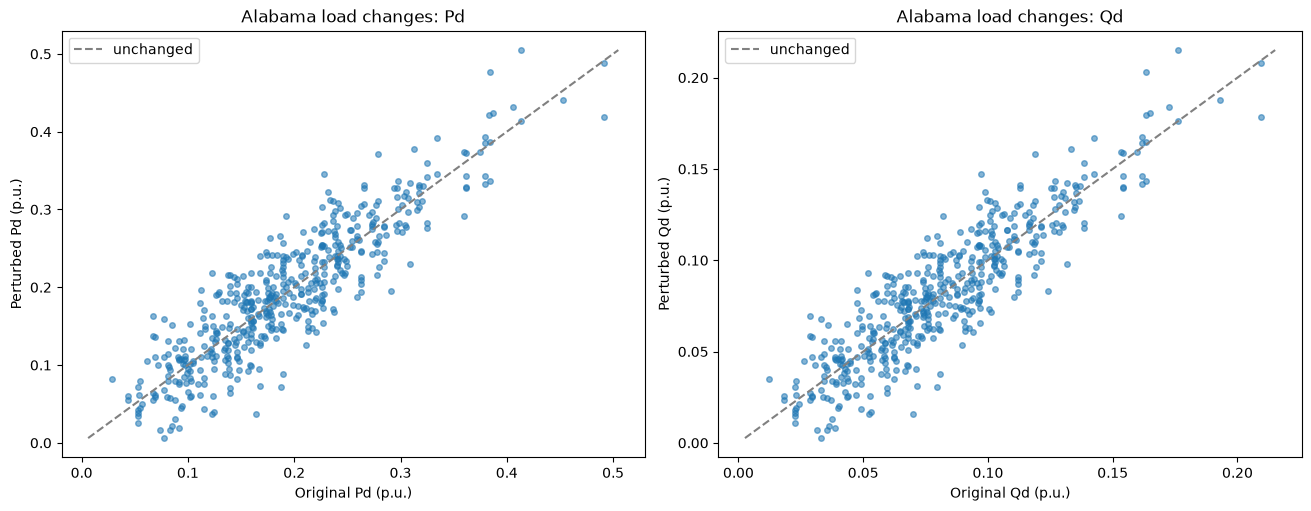

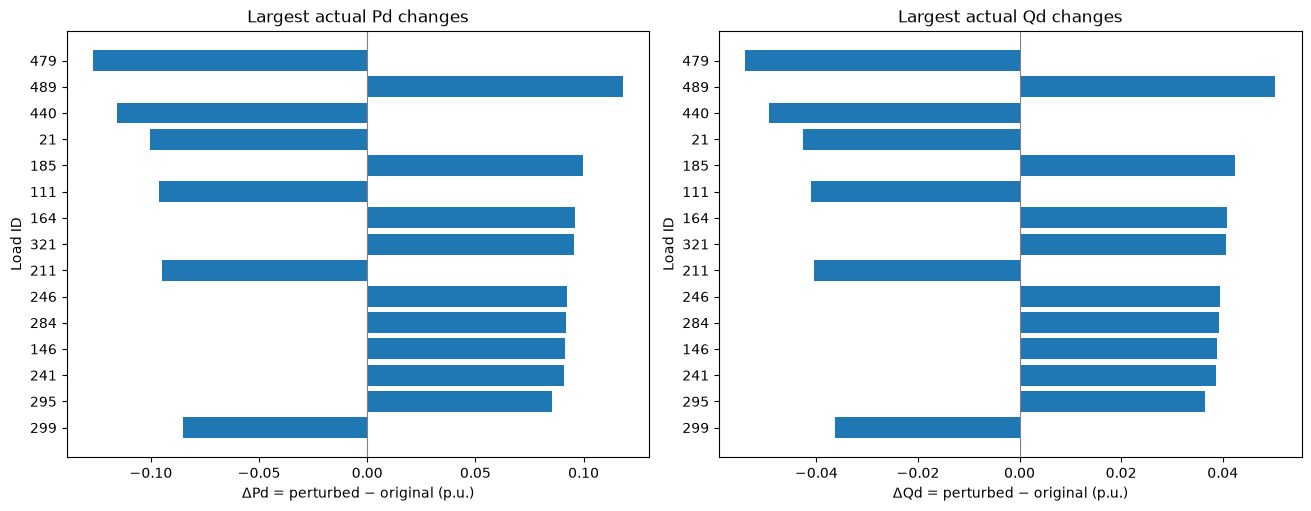

In [8]:
# Plot original vs perturbed values separately for Pd and Qd.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    axs[j].scatter(original[:, j], chosen[:, j], s=16, alpha=0.55)
    low = float(min(original[:, j].min(), chosen[:, j].min()))
    high = float(max(original[:, j].max(), chosen[:, j].max()))
    axs[j].plot([low, high], [low, high], ls="--", color="gray", label="unchanged")
    axs[j].set(xlabel=f"Original {name} (p.u.)", ylabel=f"Perturbed {name} (p.u.)",
               title=f"{DATASET_LABEL} load changes: {name}")
    axs[j].legend(loc="best")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "00_original_vs_perturbed_pd_qd.svg", bbox_inches="tight")
plt.show()

# Most-changed loads, by absolute value within each channel (not model importance).
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    take = np.argsort(np.abs(delta[:, j]))[-15:][::-1]
    d = delta[take, j][::-1]
    axs[j].barh([str(pyg_load_ids[r]) for r in take[::-1]], d)
    axs[j].axvline(0, color="gray", lw=.8)
    axs[j].set(xlabel=f"Δ{name} = perturbed − original (p.u.)",
               ylabel="Load ID", title=f"Largest actual {name} changes")
fig.savefig(EXPLAIN_DIR / "00_top_load_changes.png", dpi=180, bbox_inches="tight")
plt.show()


## 4 GridSFM forward function: always recalculate load-dependent graph features

**Crucial:** GridSFM preprocessing computes DC-based node features and `g_ctx` from the current loads. Reusing a prepared base graph while modifying just `load.x` would create internally inconsistent model inputs. This wrapper clones the **raw** graph, replaces each load's Pd/Qd, then runs `prepare_for_inference` again for every Captum perturbation. This preserves the exact released checkpoint's inference pipeline. It is slower but scientifically more defensible.

The scalar being explained is the **pretrained model's probability of AC-OPF feasibility**, not the solver objective and not Julia's verdict.

In [9]:
# For reproducible inference, run single graphs; Captum's perturbations_per_eval=1 below.
def grid_probability_pygrid(pyg_load_array):
    vals = np.asarray(pyg_load_array, dtype=np.float32)
    if vals.shape != original.shape or not np.isfinite(vals).all():
        raise ValueError(f"Invalid load input {vals.shape}, expected {original.shape}.")
    # Original raw graph: topology and non-load features never change.
    g = raw_graph.clone()
    g["load"].x[:, :2] = torch.from_numpy(vals.copy())
    prepare_for_inference(g)  # Recompute DC prior features and g_ctx for these exact loads!
    g = g.to(DEVICE)
    with torch.no_grad():
        predicted = grid_model(g)
        p = torch.sigmoid(predicted.feas_logit).reshape(-1)
    return float(p[0].detach().cpu())

class LoadFeasibilityProbability(torch.nn.Module):
    """Captum input: float tensor [batch, n_loads, 2] in PyG row order."""
    def forward(self, batch_loads):
        # Full model processing is not differentiable through DC-feature preparation;
        # KernelShap and FeatureAblation are perturbation-based and need no gradients.
        values = batch_loads.detach().cpu().numpy()
        outputs = [grid_probability_pygrid(row) for row in values]
        return torch.tensor(outputs, dtype=torch.float32, device=batch_loads.device)

feasibility_fn = LoadFeasibilityProbability().eval()
p_original = grid_probability_pygrid(original)
p_selected = grid_probability_pygrid(chosen)
print(f"GridSFM baseline P(feasible): {p_original:.6f}")
print(f"GridSFM selected P(feasible): {p_selected:.6f}")
print(f"Model change: {p_selected-p_original:+.6f} probability points")
print("Julia selected accepted:", bool(julia_accepted[SCENARIO_INDEX]))
if not np.isfinite(p_selected):
    raise RuntimeError("Pretrained GridSFM probability is nonfinite.")
if n_buses < 500:
    print(f"CAUTION: {DATASET_LABEL} has {n_buses} buses; the original notebook flagged <500-bus cases as outside checkpoint guidance.")
if abs(p_selected - p_original) < 1e-5:
    print("WARNING: Nearly flat feasibility predictions. SHAP may be tiny/unstable.")


GridSFM baseline P(feasible): 0.999941
GridSFM selected P(feasible): 0.999909
Model change: -0.000033 probability points
Julia selected accepted: True
CAUTION: Alabama has 494 buses; the original notebook flagged <500-bus cases as outside checkpoint guidance.


## Visual B — What does the pretrained model predict?

This compares GridSFM's output for the original and the selected perturbed network; it also shows the *Julia verifier's recorded outcome*. A probability is a model output, not a guarantee of AC-OPF feasibility.

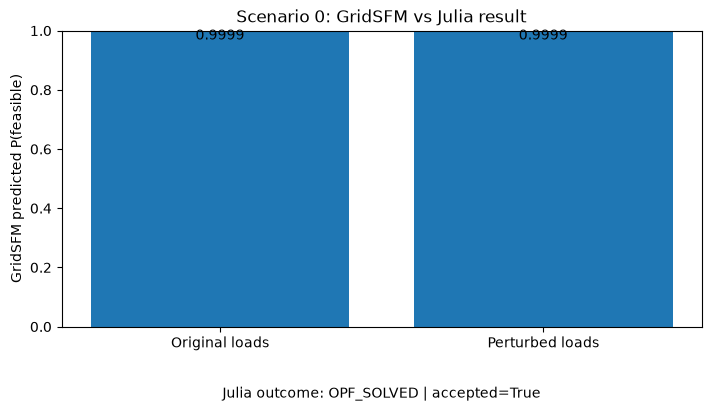

In [10]:
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
values = [p_original, p_selected]
ax.bar(["Original loads", "Perturbed loads"], values)
ax.set_ylim(0, 1)
ax.set_ylabel("GridSFM predicted P(feasible)")
ax.set_title(f"Scenario {SCENARIO_INDEX}: GridSFM vs Julia result")
for x, val in enumerate(values):
    ax.text(x, min(float(val) + .03, .97), f"{val:.4f}", ha="center")
ax.text(.5, -.24, f"Julia outcome: {saved_status[SCENARIO_INDEX]} | accepted={bool(julia_accepted[SCENARIO_INDEX])}",
        ha="center", transform=ax.transAxes, fontsize=10)
fig.savefig(EXPLAIN_DIR / "02_feasibility_before_after.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "02_feasibility_before_after.svg", bbox_inches="tight")
plt.show()

## 5. Captum Kernel SHAP — Pd vs Qd grouped across the selected grid

Explaining all individual load entries with Kernel SHAP directly is expensive. Group loads into up to **12 balanced groups** (Pd and Qd separately). When valid `lon` coordinates are available for every load bus, the groups run approximately west-to-east, retaining the original longitude-group interpretation. Otherwise, use **non-geographic PyG-row groups** and label them clearly (do **not** interpret those groups geographically).

For each masked group/channel feature, Captum restores the corresponding original values while leaving other sampled features unchanged. This is a local SHAP approximation for **this one network scenario**. Intermediate counterfactual combinations are *not* individually Julia-validated. Start with `N_SHAP_SAMPLES=64` and increase when needed.


In [11]:
N_BANDS = min(12, n_loads)  # Up to 12 nonempty groups for any grid size
N_SHAP_SAMPLES = 64        # Increase for more accurate Kernel SHAP estimates

# Stable ranking avoids empty groups when longitude values tie.
# Without longitude, group PyG rows (a non-geographic fallback).
ordered_rows = (np.argsort(longitudes, kind="stable")
                if longitudes is not None else np.arange(n_loads))
band_idx = np.empty(n_loads, dtype=int)
band_idx[ordered_rows] = (np.arange(n_loads) * N_BANDS) // n_loads
assert band_idx.min() == 0 and band_idx.max() == N_BANDS - 1
assert np.all(np.bincount(band_idx, minlength=N_BANDS) > 0)

# Each group/channel pair is a separate Captum feature.
feature_mask = np.zeros((1, n_loads, 2), dtype=np.int64)
feature_mask[0, :, 0] = 2 * band_idx
feature_mask[0, :, 1] = 2 * band_idx + 1
feature_mask_t = torch.from_numpy(feature_mask)

x_input = torch.tensor(chosen[None, ...], dtype=torch.float32)
x_base = torch.tensor(original[None, ...], dtype=torch.float32)

kernel_shap = KernelShap(feasibility_fn)
shap_t = kernel_shap.attribute(
    x_input, baselines=x_base, feature_mask=feature_mask_t,
    n_samples=N_SHAP_SAMPLES, perturbations_per_eval=1,
    show_progress=True,
)
shap_grid = shap_t.squeeze(0).detach().cpu().numpy()
shap_band = np.array([
    [float(shap_grid[band_idx == g, j].mean()) for j in range(2)]
    for g in range(N_BANDS)
])
# Captum broadcasts a group attribution to all group members;
# averaging recovers the group attribution. Summing would overcount it.
assert np.isfinite(shap_band).all(), "Nonfinite SHAP. Investigate model numerical behavior."
print("Group SHAP shape:", shap_band.shape, "| grouping:", GROUPING_METHOD)
print("Positive: increases GridSFM predicted feasibility vs original loads")
print("Negative: decreases GridSFM predicted feasibility vs original loads")


Kernel Shap attribution: 100%|██████████| 64/64 [00:20<00:00,  3.11it/s]


Group SHAP shape: (12, 2) | grouping: longitude_rank_quantiles
Positive: increases GridSFM predicted feasibility vs original loads
Negative: decreases GridSFM predicted feasibility vs original loads


## 6. Visualize group-level Pd/Qd Kernel SHAP

The chart shows which **load group** and channel (Pd/Qd) contributed to a change in the pretrained model's prediction. When `GROUPING_METHOD` is longitude-based, groups are approximate west-to-east bands; otherwise they are explicitly **non-geographic**. Negative SHAP means reduced predicted probability, **not** a proof of physical infeasibility.


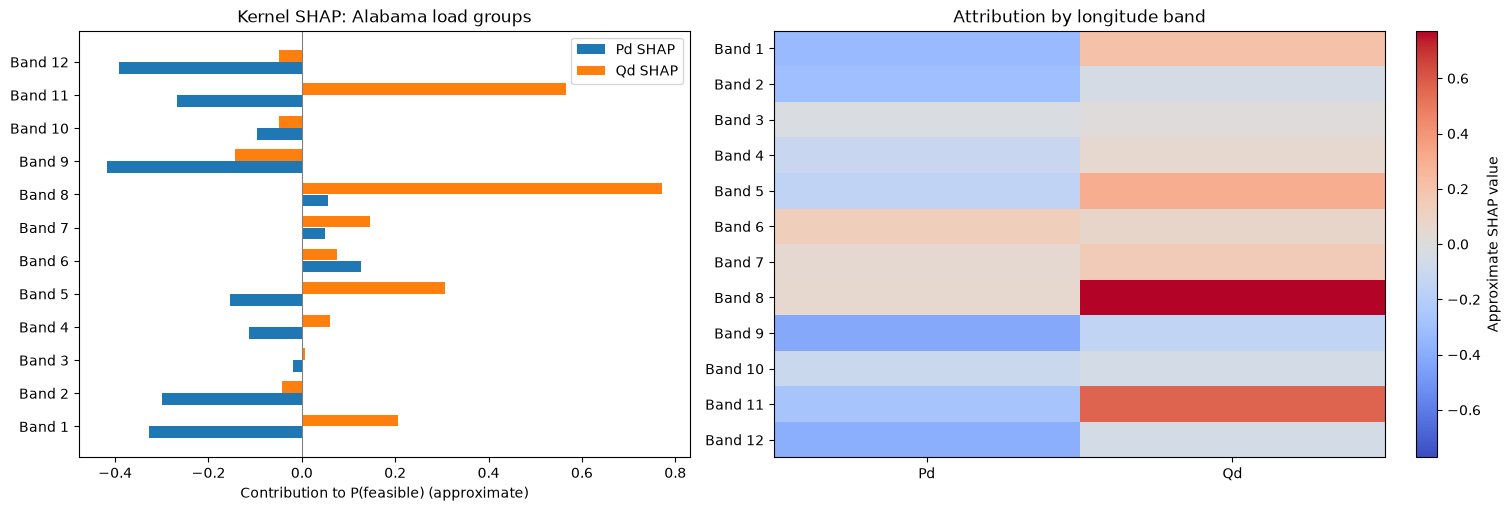

Top groups by |SHAP|:
{'group': 8, 'group_label': 'Band 8', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 41, 'longitude_min': -86.5572109, 'longitude_max': -86.3462574, 'pd_shap': 0.056450437754392624, 'qd_shap': 0.7723543643951416, 'total_delta_pd_pu': -0.60191810131073, 'total_delta_qd_pu': -0.2565850019454956}
{'group': 11, 'group_label': 'Band 11', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 41, 'longitude_min': -85.83548995, 'longitude_max': -85.39151035, 'pd_shap': -0.2670830488204956, 'qd_shap': 0.5648733973503113, 'total_delta_pd_pu': -0.04271010309457779, 'total_delta_qd_pu': -0.018179714679718018}
{'group': 9, 'group_label': 'Band 9', 'grouping_method': 'longitude_rank_quantiles', 'n_loads': 41, 'longitude_min': -86.34569146666666, 'longitude_max': -86.0710254, 'pd_shap': -0.4184495806694031, 'qd_shap': -0.14329195022583008, 'total_delta_pd_pu': 0.1641199290752411, 'total_delta_qd_pu': 0.06985557079315186}
{'group': 12, 'group_label': 'Band 12', 'gr

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
ys = np.arange(N_BANDS)
labels = [f"{GROUP_LABEL} {i+1}" for i in ys]
ax1.barh(ys - 0.18, shap_band[:, 0], height=0.35, label="Pd SHAP")
ax1.barh(ys + 0.18, shap_band[:, 1], height=0.35, label="Qd SHAP")
ax1.axvline(0, color="gray", linewidth=0.8)
ax1.set_yticks(ys, labels)
ax1.set_xlabel("Contribution to P(feasible) (approximate)")
ax1.set_title(f"Kernel SHAP: {DATASET_LABEL} load groups")
ax1.legend()

vmax = max(float(np.abs(shap_band).max()), 1e-8)
im = ax2.imshow(shap_band, cmap="coolwarm", aspect="auto", vmin=-vmax, vmax=vmax)
ax2.set_xticks([0, 1], ["Pd", "Qd"])
ax2.set_yticks(ys, labels)
ax2.set_title("Attribution by longitude band" if longitudes is not None else
              "Attribution by PyG-row group (non-geographic)")
fig.colorbar(im, ax=ax2, label="Approximate SHAP value")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "01_group_shap_bar_and_heatmap.svg", bbox_inches="tight")
plt.show()

band_table = []
for i in range(N_BANDS):
    members = band_idx == i
    band_table.append({
        "group": i + 1,
        "group_label": f"{GROUP_LABEL} {i+1}",
        "grouping_method": GROUPING_METHOD,
        "n_loads": int(members.sum()),
        "longitude_min": (float(longitudes[members].min()) if longitudes is not None else None),
        "longitude_max": (float(longitudes[members].max()) if longitudes is not None else None),
        "pd_shap": float(shap_band[i, 0]), "qd_shap": float(shap_band[i, 1]),
        "total_delta_pd_pu": float(delta[members, 0].sum()),
        "total_delta_qd_pu": float(delta[members, 1].sum()),
    })
print("Top groups by |SHAP|:")
for entry in sorted(band_table, key=lambda row: max(abs(row["pd_shap"]), abs(row["qd_shap"])),
                    reverse=True)[:8]:
    print(entry)


## Visual C — Ranked group/channel SHAP contributions (local explanation)

Each bar is a **group/channel**, not one load. Positive/negative values shift the pretrained model's predicted feasibility relative to the selected dataset's original loads. Group values are **not** individual-load SHAP scores. Summed attributions are approximate and may differ from the measured model-probability change.


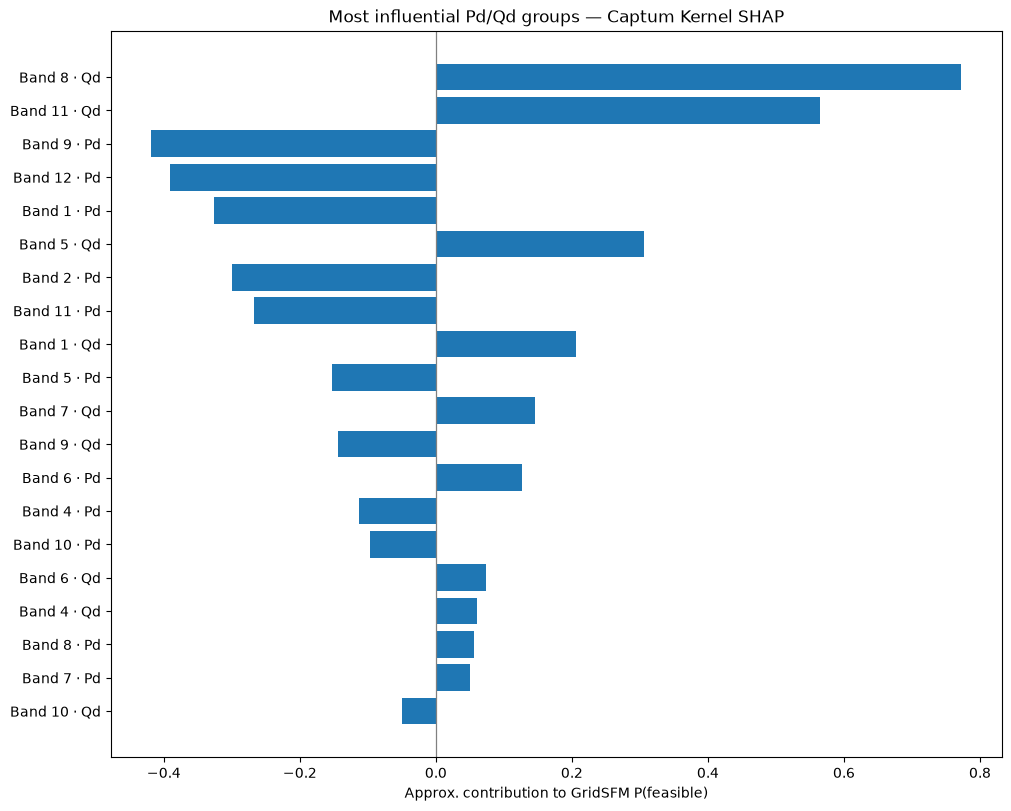

Model P(feasible) difference: -3.3e-05
Sum of group SHAP contributions (approx.): -3.4e-05
Gap (attribution estimate − model difference): -1e-06
Total absolute group attribution: Pd= 2.318883 Qd= 2.423389


In [13]:
labels = [f"{GROUP_LABEL} {g+1} · {channel}" for g in range(N_BANDS) for channel in ("Pd", "Qd")]
values = shap_band.reshape(-1)
ranked = np.argsort(np.abs(values))[::-1][:min(20, len(values))]
ranked = ranked[::-1]  # largest magnitudes at the top
fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
ax.barh([labels[k] for k in ranked], values[ranked])
ax.axvline(0, lw=.9, color="gray")
ax.set_xlabel("Approx. contribution to GridSFM P(feasible)")
ax.set_title("Most influential Pd/Qd groups — Captum Kernel SHAP")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "03_ranked_group_shap.svg", bbox_inches="tight")
plt.show()

print("Model P(feasible) difference:", round(p_selected-p_original, 6))
print("Sum of group SHAP contributions (approx.):", round(float(values.sum()), 6))
print("Gap (attribution estimate − model difference):", round(float(values.sum()-(p_selected-p_original)), 6))
print("Total absolute group attribution: Pd=", round(float(np.abs(shap_band[:,0]).sum()),6),
      "Qd=", round(float(np.abs(shap_band[:,1]).sum()),6))


## 7 Which **individual loads** should we investigate?

Kernel SHAP above explains **up to 24 group/channel features** (12 groups × Pd/Qd). The following inexpensive follow-up uses **Captum `FeatureAblation`**, not SHAP, to estimate individual-load effects for the 12 loads with the largest absolute changes in the **most influential group**. It replaces one selected load's Pd or Qd with its original value while keeping all other perturbations. The reported difference is local and conditional, so do not call it a true per-load SHAP value.

Increase `TOP_K_LOADS` for a broader follow-up. For exact all-load attribution, use many more model evaluations and repeated independent explanations.


In [14]:
TOP_K_LOADS = 12
strongest_feature = int(np.abs(shap_band).argmax())
strongest_band, strongest_channel = np.unravel_index(strongest_feature, shap_band.shape)
within = np.flatnonzero(band_idx == strongest_band)
score = np.abs(delta[within, strongest_channel])
selected_pyg_rows = within[np.argsort(score)[-min(TOP_K_LOADS, len(within)):][::-1]]
print("Selected influential group:", f"{GROUP_LABEL} {strongest_band + 1}",
      "channel:", ["Pd", "Qd"][strongest_channel])
print("Inspecting", len(selected_pyg_rows), "individual loads")

# Only explain these 12 load/channel entries. Other inputs remain constant;
# assigning a common mask ID to other loads would ablate them as a huge group,
# so instead use a focused parameterization on a vector of K changes.
feature_pairs = [(int(r), int(j)) for r in selected_pyg_rows for j in (0, 1)]

def focused_forward(z):
    # Each row z contains the chosen load/channel values; other loads remain
    # at the chosen sampled values. Baseline for these features = original values.
    outputs = []
    for z_row in z.detach().cpu().numpy():
        test = chosen.copy()
        for k, (r, j) in enumerate(feature_pairs):
            test[r, j] = float(z_row[k])
        outputs.append(grid_probability_pygrid(test))
    return torch.tensor(outputs, dtype=torch.float32, device=z.device)

focus_x = torch.tensor([[chosen[r,j] for r,j in feature_pairs]], dtype=torch.float32)
focus_base = torch.tensor([[original[r,j] for r,j in feature_pairs]], dtype=torch.float32)
focus_attr = FeatureAblation(focused_forward).attribute(
    focus_x, baselines=focus_base, perturbations_per_eval=1,
    show_progress=True,
).squeeze(0).numpy()

individual_table = []
for k, ((r,j), impact) in enumerate(zip(feature_pairs, focus_attr)):
    individual_table.append({
        "pyg_row": int(r), "load_id": pyg_load_ids[r],
        "bus_id": pyg_load_bus_id[r], "bus_name": data["bus"][pyg_load_bus_id[r]].get("name", ""),
        "channel": ["Pd", "Qd"][j],
        "original_pu": float(original[r,j]),
        "perturbed_pu": float(chosen[r,j]),
        "change_pu": float(delta[r,j]),
        "ablation_effect": float(impact),
    })
individual_table.sort(key=lambda r: abs(r["ablation_effect"]), reverse=True)
print("Top individual load effects (FeatureAblation, NOT per-load SHAP):")
for row in individual_table[:15]:
    print(row)


Selected influential group: Band 8 channel: Qd
Inspecting 12 individual loads


Feature Ablation attribution: 100%|██████████| 25/25 [00:07<00:00,  3.23it/s]

Top individual load effects (FeatureAblation, NOT per-load SHAP):
{'pyg_row': 313, 'load_id': '314', 'bus_id': '354', 'bus_name': 'BUS_354', 'channel': 'Qd', 'original_pu': 0.0331207700073719, 'perturbed_pu': 0.002613084390759468, 'change_pu': -0.030507685616612434, 'ablation_effect': 0.004567265510559082}
{'pyg_row': 56, 'load_id': '57', 'bus_id': '4', 'bus_name': 'Montgomery Switching Station', 'channel': 'Qd', 'original_pu': 0.03634864464402199, 'perturbed_pu': 0.009110149927437305, 'change_pu': -0.027238495647907257, 'ablation_effect': 0.0021619200706481934}
{'pyg_row': 313, 'load_id': '314', 'bus_id': '354', 'bus_name': 'BUS_354', 'channel': 'Pd', 'original_pu': 0.0777486115694046, 'perturbed_pu': 0.006111210212111473, 'change_pu': -0.07163739949464798, 'ablation_effect': -4.2319297790527344e-05}
{'pyg_row': 411, 'load_id': '412', 'bus_id': '563', 'bus_name': 'U S Alliance Coosa Pines Cogen', 'channel': 'Qd', 'original_pu': 0.05941155180335045, 'perturbed_pu': 0.0270710326731205, 

## Visual D — Individual load changes that matter to GridSFM

This plot uses **Feature Ablation**, not Kernel SHAP. It takes the most perturbed loads within the strongest SHAP group, and compares the pretrained model's output with one Pd/Qd value reverted to its original value. Values reflect the model's dependence on that change **in the context of all other perturbations**.

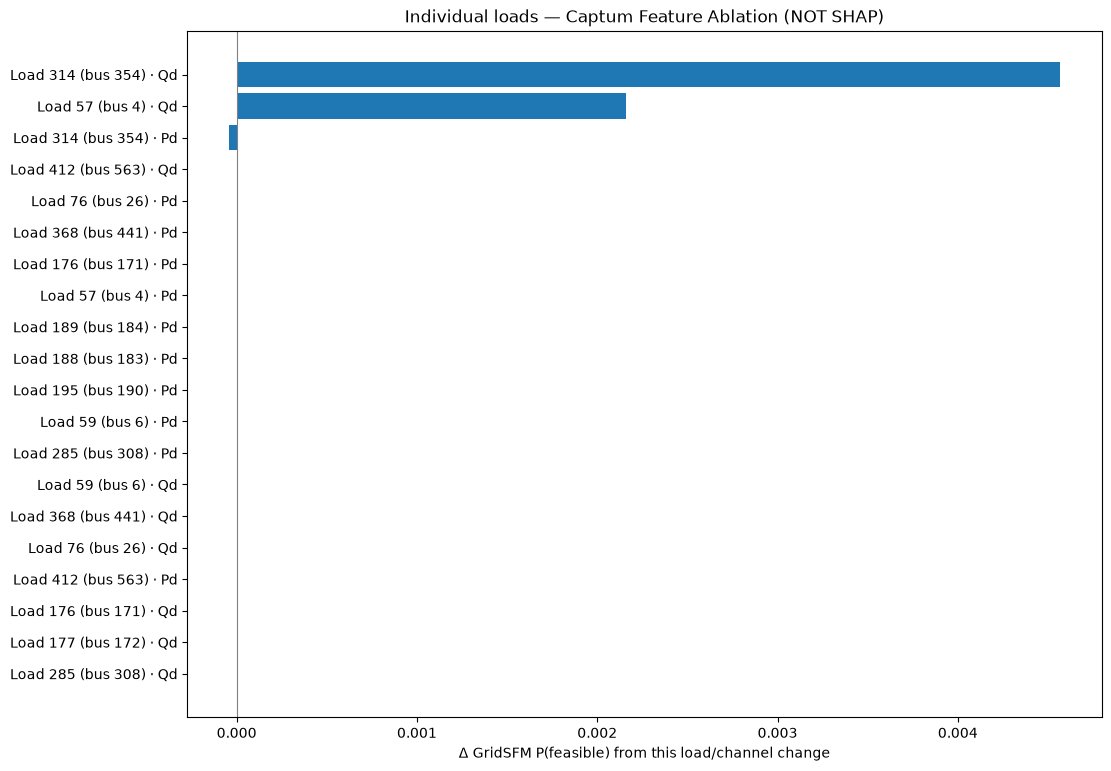

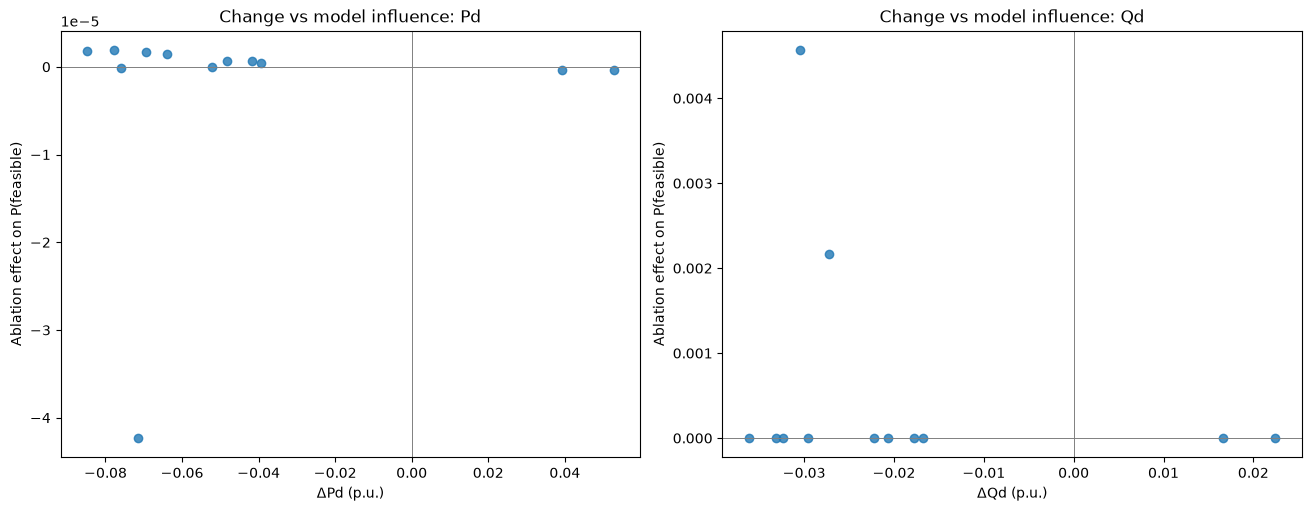

In [15]:
# Ranked individual-load ablation effects.
show = individual_table[:min(20, len(individual_table))]
fig, ax = plt.subplots(figsize=(11, max(5, len(show)*.38)), constrained_layout=True)
ax.barh([f"Load {r['load_id']} (bus {r['bus_id']}) · {r['channel']}" for r in show[::-1]],
        [r["ablation_effect"] for r in show[::-1]])
ax.axvline(0, color="gray", linewidth=.8)
ax.set_xlabel("Δ GridSFM P(feasible) from this load/channel change")
ax.set_title("Individual loads — Captum Feature Ablation (NOT SHAP)")
fig.savefig(EXPLAIN_DIR / "04_ranked_individual_load_ablation.png", dpi=180, bbox_inches="tight")
fig.savefig(EXPLAIN_DIR / "04_ranked_individual_load_ablation.svg", bbox_inches="tight")
plt.show()

# Compare actual changes with model attribution for investigated loads.
fig, axs = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for j, name in enumerate(("Pd", "Qd")):
    sub = [r for r in individual_table if r["channel"] == name]
    axs[j].scatter([r["change_pu"] for r in sub],
                   [r["ablation_effect"] for r in sub], alpha=.8)
    axs[j].axhline(0, color="gray", linewidth=.7)
    axs[j].axvline(0, color="gray", linewidth=.7)
    axs[j].set(xlabel=f"Δ{name} (p.u.)", ylabel="Ablation effect on P(feasible)",
               title=f"Change vs model influence: {name}")
fig.savefig(EXPLAIN_DIR / "05_load_change_vs_ablation_effect.png", dpi=180, bbox_inches="tight")
plt.show()

## 8. Export dataset-specific research results

Report: the before/after pretrained-model probability, the recorded Julia outcome, group/channel Kernel SHAP attribution, and individual-load Feature Ablation findings. **Do not** interpret either attribution technique as proof that a particular bus caused an AC-OPF failure.


In [16]:
import csv
EXPLAIN_DIR.mkdir(parents=True, exist_ok=True)

def write_csv(path, rows):
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
        w.writeheader(); w.writerows(rows)

write_csv(EXPLAIN_DIR / "pd_qd_group_kernelshap.csv", band_table)
write_csv(EXPLAIN_DIR / "pd_qd_load_feature_ablation.csv", individual_table)
summary = {
    "dataset_name": DATASET_NAME,
    "dataset_label": DATASET_LABEL,
    "source_case_sha256": CASE_SHA256,
    "n_buses": n_buses,
    "n_active_loads": n_loads,
    "grouping_method": GROUPING_METHOD,
    "load_mapping_source": load_mapping_source,
    "checkpoint": str(CHECKPOINT_PATH),
    "pyg_case": str(PYG_PATH),
    "source_case": str(DATA_PATH.resolve()),
    "selected_scenario_index": int(SCENARIO_INDEX),
    "iteration": int(saved_iteration[SCENARIO_INDEX]),
    "scenario": int(saved_scenario[SCENARIO_INDEX]),
    "julia_accepted": bool(julia_accepted[SCENARIO_INDEX]),
    "julia_status": str(saved_status[SCENARIO_INDEX]),
    "gridsfm_original_p_feasible": float(p_original),
    "gridsfm_perturbed_p_feasible": float(p_selected),
    "gridsfm_delta_p_feasible": float(p_selected - p_original),
    "n_bands": int(N_BANDS),
    "kernelshap_samples": int(N_SHAP_SAMPLES),
    "method_group": f"Captum KernelShap with {GROUPING_METHOD} Pd/Qd grouping",
    "method_individual": "Captum FeatureAblation on selected load/channels (not SHAP)",
    "interpretation_warning": ("Attributions explain GridSFM predictions, not physical AC-OPF causation. "
                               + (f"Selected grid has {n_buses} buses (<500); check checkpoint applicability."
                                  if n_buses < 500 else "Validate checkpoint applicability for this grid.")),
}
with (EXPLAIN_DIR / "run_summary.json").open("w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Saved explanation files under:", EXPLAIN_DIR.resolve())


Saved explanation files under: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_load_centered/alabama/pretrained_gridsfm_captum


## 9. Reading the explanations

- **Negative group Pd attribution**: under the selected baseline/masking procedure, those active-power perturbations reduced the pretrained GridSFM predicted feasibility relative to the original selected grid.
- **Positive group Qd attribution**: those reactive-power perturbations increased the predicted probability, *not* the Julia solver's verified feasibility.
- **Individual `ablation_effect`**: effect on the model's output when the selected load/channel is restored to its original value while other loads stay perturbed. **Feature Ablation is not per-load SHAP.**
- **Group geography** is only meaningful when `GROUPING_METHOD == "longitude_rank_quantiles"`. Otherwise groups are non-geographic row-order partitions.
- The model is **pretrained**, so no state-specific surrogate weights or two-class Julia training labels are needed. Julia labels are useful for comparison.
- These are **local counterfactual explanations of model behavior**, not physical proof of AC-OPF infeasibility. For physical testing, restore candidate loads individually and rerun the Julia AC-OPF verifier.
- Inspect `n_buses` and your checkpoint's applicability before comparing states; a model trained for one network regime may not generalize reliably to every state/grid size.
